# Code for Task 3 : Figure 3
Since the shot style figure was made with the season 2022-2023, let's do that figure with that season too.

In [1]:
from ift6758.features.simple_visualizations import games_list,distance
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
import seaborn as sns

In [2]:
df2022 = games_list(2022)
df_dist = distance(df2022)

Pourcentage de buts pour ce type de shot à cette distance

grouby distance par bins

calculer les pourcentages par bin de distance et type de shot

In [ ]:
max = round(np.max(df_dist["distance"]),-2)
min = round(np.min(df_dist["distance"]),-2)
print(min)
print(max)

0.0
200.0


I choose to make bins of 20.
I need 10 bins.

In [12]:
# Copy to avoid pandas warnings when adding a column
df_dist = df_dist.copy()

# Create a boolean column to know if the event is a goal
df_dist["is_goal"] = df_dist["event_type"] == "goal"

#Group by distance
nb_bins = 20
freq = (max-min)/nb_bins
interval = pd.interval_range(min,max,freq=freq,closed="left")

bins = pd.cut(df_dist['distance'],interval)
bins = bins.rename("bins")

df = pd.concat([df_dist,bins],axis=1)

shot_type = df["shot_type"].drop_duplicates().dropna()
shot_type = np.array(shot_type)

df_shot_type = []
for type in shot_type:
    df_type = df[df["shot_type"]==type]

    df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
    df_type = df_type.rename(columns={"size":"shots","sum":"goals"})  

    df_shot_type.append(df_type)

# Percentage of shots that became goals
for df in df_shot_type:
    df["pourcentage"] = df["goals"] / df["shots"] * 100
    # df["pourcentage"] = df["pourcentage"].replace(0,None)

print(df_shot_type[7])
# df_shot_type.pop(10)
# df_shot_type.pop(7)

C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\2099770139.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\2099770139.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\2099770139.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt th

                shots  goals  pourcentage
bins                                     
[0.0, 10.0)       291     53    18.213058
[10.0, 20.0)       86      6     6.976744
[20.0, 30.0)       19      2    10.526316
[30.0, 40.0)        8      2    25.000000
[40.0, 50.0)        4      1    25.000000
[50.0, 60.0)        2      0     0.000000
[60.0, 70.0)        3      0     0.000000
[70.0, 80.0)        4      0     0.000000
[80.0, 90.0)        3      0     0.000000
[90.0, 100.0)       1      0     0.000000
[100.0, 110.0)      0      0          NaN
[110.0, 120.0)      0      0          NaN
[120.0, 130.0)      0      0          NaN
[130.0, 140.0)      1      1   100.000000
[140.0, 150.0)      0      0          NaN
[150.0, 160.0)      0      0          NaN
[160.0, 170.0)      0      0          NaN
[170.0, 180.0)      0      0          NaN
[180.0, 190.0)      0      0          NaN
[190.0, 200.0)      0      0          NaN


C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\2099770139.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\2099770139.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])


C:\Users\tiffa\AppData\Local\Temp\ipykernel_3520\881404251.py:20: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#controlling-the-legend-entries
  plt.legend(shot_type,colors)


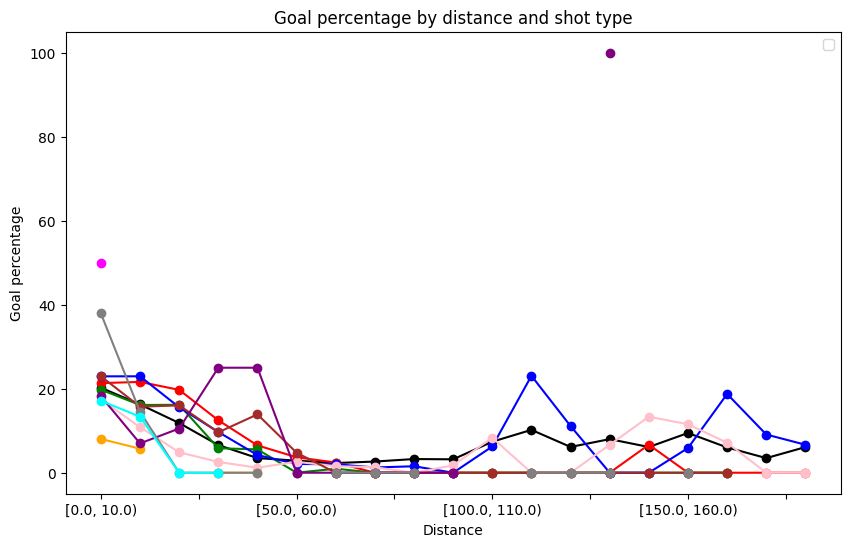

In [13]:
colors = np.array(["black","red","green","blue","pink","orange","brown","purple","gray","cyan","magenta"])

plt.subplots(figsize=(10, 6))

# plt_df = pd.DataFrame(interval,columns=["bins"])
# plt_df["pourcentage"] = df_shot_type[0]["pourcentage"].values

# print(plt_df)


for i in range(len(df_shot_type)):
    # plt_df = pd.DataFrame(interval,columns=["bins"])
    # plt_df["pourcentage"] = df_shot_type[0]["pourcentage"].values   
    df_shot_type[i]["pourcentage"].plot(marker='o', c=colors[i])

plt.title("Goal percentage by distance and shot type")
plt.xlabel("Distance")
plt.ylabel("Goal percentage")

plt.legend(shot_type,colors)

plt.show()

Briefly discuss your findings; e.g. what might be the most dangerous types of shots?

Comme attendu, la distance des tirs est toujours plus grande que la distances des buts.

On peut observer différents écarts entre la distance moyenne des buts et celles des tirs.

On peut notamment conclure que le wrap-around est un type de tirs qui se fait à une petite distance, que cela fasse un but ou non.

On peut réaffirmer aussi qu'il y a plus de chance de faire un buts à partir d'une petite distance, qu'une grande distance.

Le type de tir le plus dangereux est le cradle, avec 50% de buts. Ensuite, ce serait le bat.
